# Task 2.2: phase flip rate $\Gamma_Z$

**Answer.** At $\alpha=2.1$, $\Gamma_Z=0.5146\ \mu\mathrm{s}^{-1}$: a parity-relaxation time $1/\Gamma_Z=1.94$ µs. That is $1.3\times10^{6}$ times faster than a bit flip (Task 2.1), which is the noise bias that makes cat qubits useful. There, time domain fits and the Liouvillian eigenvalue agree to $4\times10^{-8}$.

**Definition.** Start in the even cat $\lvert C_+\rangle\propto\lvert\alpha\rangle+\lvert-\alpha\rangle$ with the buffer empty and $\epsilon_d=g_2\alpha^2$. Each lost memory photon flips the parity $\Pi=(-1)^{a^\dagger a}$, so we fit

$$\langle\Pi\rangle(t)=\Pi_\infty+A e^{-\Gamma_Z t},\qquad t\ge1\ \mu\mathrm{s}.$$

The offset $\Pi_\infty$ is fitted because the two parity sectors have unequal stationary weights at finite cat size. $\Gamma_Z$ is their population-relaxation rate, the sum of the even-to-odd and odd-to-even transition rates; its inverse is not the mean interval between individual photon-loss events. Saved results load by default; set `RERUN=True` to recompute.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
from IPython.display import Image, display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/config.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from research.s2 import notebook_figs as F
RERUN = False

## 1. Brute force: parity decay

α,Γ_Z (1/µs),1/Γ_Z (µs),Γ_Z / 2κ_aα²,Π_∞ fit,sech 2α²,Γ_Z if Π_∞ = 0,α² − n̄
1.2,0.168535,5.93,1.0015,1.1e-01,1.1e-01,0.0928,0.0173
1.5,0.262159,3.81,0.9970,2.3e-02,2.2e-02,0.2302,0.0081
1.8,0.377814,2.65,0.9978,3.2e-03,3.1e-03,0.3692,0.0072
2.1,0.514559,1.94,0.9984,3.2e-04,3.0e-04,0.5131,0.0071
2.4,0.672337,1.49,0.9988,2.0e-05,2.0e-05,0.6722,0.0070


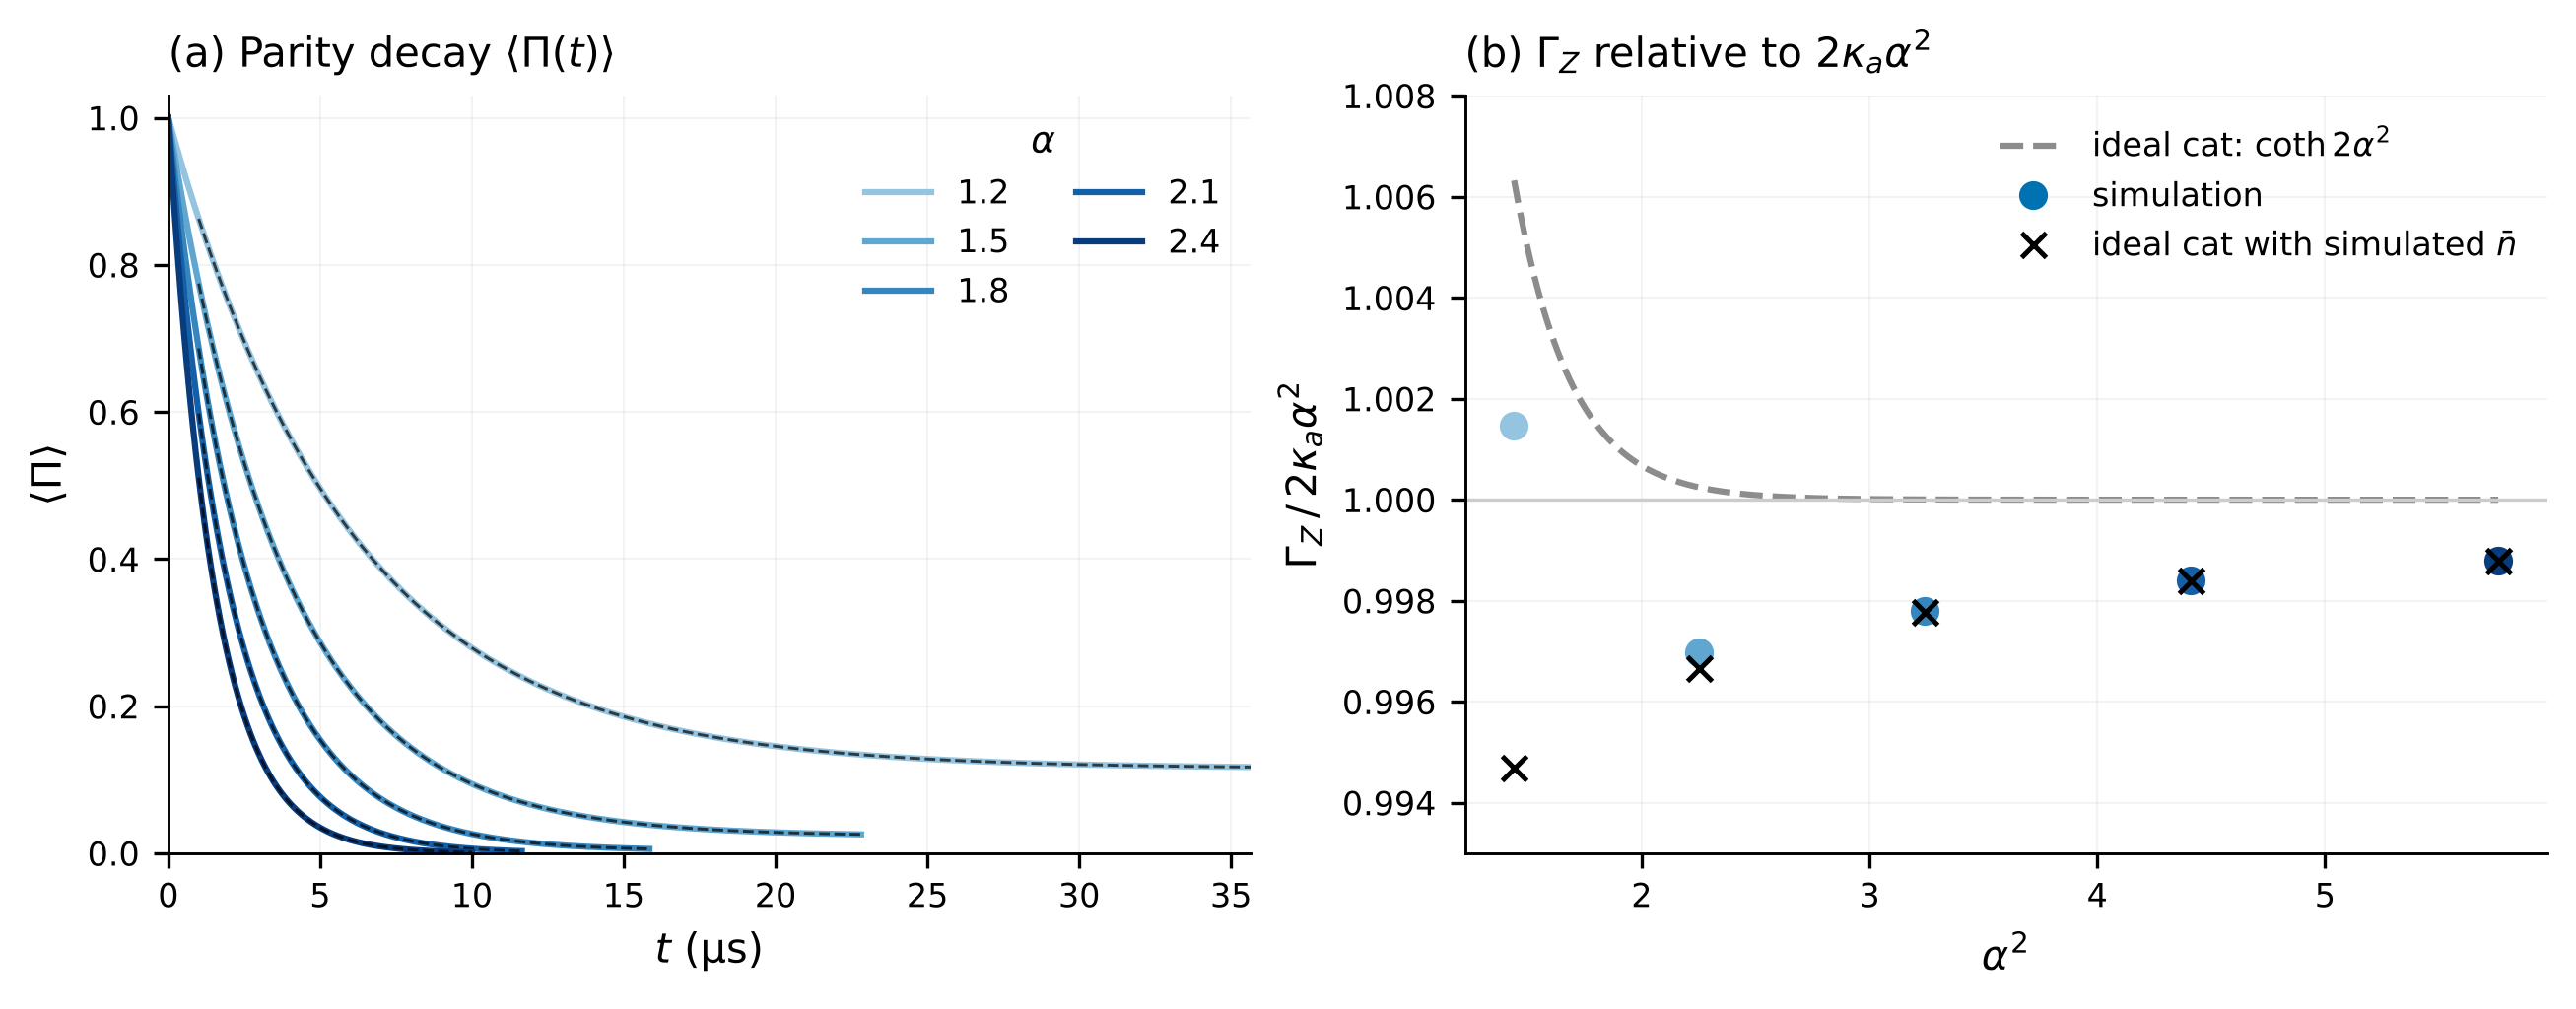

In [2]:
if RERUN:
    from tasks.task_2_2 import main
    main()
result = json.loads((ROOT / "results/task_2_2.json").read_text())
assert result["complete"]
traj = np.load(ROOT / "results/task_2_2_trajectories.npz")
kappa_a = result["kappa_a_per_us"]
nbar = [float(np.real(traj[f"e_{i}"][2][-1])) for i in range(len(result["cases"]))]
display(pd.DataFrame([{
    "α": r["alpha"], "Γ_Z (1/µs)": f"{r['fit']['gamma_per_us']:.6f}", "1/Γ_Z (µs)": f"{r['fit']['tau_us']:.2f}",
    "Γ_Z / 2κ_aα²": f"{r['fit']['gamma_per_us'] / (2 * kappa_a * r['alpha2']):.4f}",
    "Π_∞ fit": f"{r['fit']['offset']:.1e}", "sech 2α²": f"{1 / np.cosh(2 * r['alpha2']):.1e}",
    "Γ_Z if Π_∞ = 0": f"{r['zero_offset_fit']['gamma_per_us']:.4f}",
    "α² − n̄": f"{r['alpha2'] - n:.4f}",
} for r, n in zip(result["cases"], nbar)]).style.hide(axis="index").format({"α": "{:g}"}))
display(Image(filename=str(ROOT / "figures/task_2_2_phase_flips.png"), width=1000))

**Parity decay.** Full two-mode model at truncation $(N_a,N_b)=(24,8)$. (a) $\langle\Pi\rangle$ from the even cat. Colored lines are trajectories; black dashes are fits from 1 µs. (b) $\Gamma_Z$ divided by the large-cat estimate $2\kappa_a\alpha^2$. Gray dashes are the ideal cat prediction $\coth2\alpha^2$. Crosses are the same prediction using the photon number $\bar n$ the simulation actually holds.

**Why $2\kappa_a\alpha^2$.** In the ideal cat space, one photon loss takes even to odd at rate $\kappa_a\alpha^2\tanh\alpha^2$ and odd to even at $\kappa_a\alpha^2\coth\alpha^2$. Together they give

$$\Gamma_Z=2\kappa_a\alpha^2\coth2\alpha^2,\qquad \Pi_\infty=\operatorname{sech}2\alpha^2,$$

which tend to $2\kappa_a\alpha^2$ and 0 for large cats. The rate grows with cat size because a bigger cat loses photons faster.

**What the simulation adds.**
- **The cat is slightly smaller than $\alpha^2$.** Photon loss competes with the pump, so the memory holds $\bar n\approx\alpha^2-0.007$ photons. That makes $\Gamma_Z$ 0.1 to 0.3% below $\coth2\alpha^2$. With the simulated $\bar n$, the ideal formula matches to $3\times10^{-4}$ for $\alpha\ge1.5$ (crosses). At $\alpha=1.2$ the cats overlap too much for this picture.
- **The offset matters.** Forcing $\Pi_\infty=0$ biases $\Gamma_Z$ by 45% at $\alpha=1.2$ and 0.3% at $\alpha=2.1$.

**Checks.** At each $\alpha$, the fit is compared with the even-block eigenvalue at the same truncation, an independent dynamiqs integration and other fit windows. The last column is the largest population on the top memory and buffer levels.

In [3]:
display(pd.DataFrame([{
    "α": r["alpha"],
    "fit vs eigenvalue": f"{r['checks']['fit_vs_eigen_relative_change']:.0e}",
    "fit vs dynamiqs": f"{r['checks']['dynamiqs_rate_relative_change']:.0e}",
    "fit window spread": f"{r['checks']['window_relative_spread']:.0e}",
    "change at larger cutoff": f"{r['checks']['cutoff_relative_change']:.0e}",
    "top level population": f"{max(r['diagnostics']['max_top2_a'], r['diagnostics']['max_top1_b']):.0e}",
} for r in result["cases"]]).style.hide(axis="index").format({"α": "{:g}"}))

α,fit vs eigenvalue,fit vs dynamiqs,fit window spread,change at larger cutoff,top level population
1.2,5e-10,2e-08,1e-06,4e-09,6e-12
1.5,5e-09,3e-08,4e-07,3e-09,4e-10
1.8,2e-08,1e-08,9e-07,3e-09,2e-09
2.1,2e-08,1e-08,9e-07,2e-07,4e-09
2.4,5e-08,2e-10,2e-06,3e-06,3e-07


## 2. Cross-check: the eigenvalue

$\Gamma_Z$ is identified with $-\mathrm{Re}\lambda$ of the slow nonzero even mode that matches the parity decay. We extract candidate eigenvalues near zero with the same sparse method as in Task 2.1 (`research/s2/gx_eig.py`), at larger truncations. The independent time domain fit checks that this mode governs the measured parity relaxation.

In [4]:
eig = F.largest(d for d in F.load("gx_two_*.json") if F.nominal(d) and "gamma_z_eig" in d)
display(pd.DataFrame([{
    "α": c["alpha"], "time domain fit, 24×8": f"{c['fit']['gamma_per_us']:.6f}",
    "eigenvalue": f"{eig[round(c['alpha'], 2)]['gamma_z_eig']:.6f}",
    "eigenvalue truncation": f"{eig[round(c['alpha'], 2)]['na']}×{eig[round(c['alpha'], 2)]['nb']}",
    "difference": f"{abs(eig[round(c['alpha'], 2)]['gamma_z_eig'] / c['fit']['gamma_per_us'] - 1):.0e}",
} for c in result["cases"]]).style.hide(axis="index").format({"α": "{:g}"}))

α,"time domain fit, 24×8",eigenvalue,eigenvalue truncation,difference
1.2,0.168535,0.168535,24×8,5e-09
1.5,0.262159,0.262159,28×8,1e-08
1.8,0.377814,0.377814,30×8,2e-08
2.1,0.514559,0.514559,32×8,4e-08
2.4,0.672337,0.672336,36×8,3e-06


**Result.** $\Gamma_Z(2.1)=0.5146\ \mu\mathrm{s}^{-1}$, a parity-relaxation time of 1.94 µs. Both methods agree to five digits or better at every $\alpha$. For $\alpha\ge1.5$, replacing $\alpha^2$ by the simulated mean photon number $\bar n$ in $2\kappa_a\alpha^2\coth2\alpha^2$ reproduces the fitted rate within $3\times10^{-4}$. This is an empirical comparison, not a derivation of the finite-loss correction. Together with Task 2.1, the bias at $\alpha=2.1$ is $\Gamma_Z/\Gamma_X=1.3\times10^{6}$.

Limits: no thermal photons; the 0.007 photon shift is measured, not derived.